# XGBoost Baseline — JalVaani
**Model:** XGBoost Regressor — single model, all districts, all available features  
**Purpose:** ML floor — shows non-linear feature interactions without deep temporal memory. Often beats vanilla LSTM.  
**Key output:** SHAP analysis — tells us *which features actually matter* in this data (informs TFT VSN design)  
**Split:** Train 2023-01-01 → 2024-09-30 · Val 2024-10-01 → 2025-01-31 · Test 2025-02-01 → 2025-04-22

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from pathlib import Path
from IPython.display import display

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size']  = 11

MASTER    = Path('../../Data Preprocessing/clean datasets/master_dataset.csv')
OUT_DIR   = Path('outputs')
OUT_DIR.mkdir(exist_ok=True)
(OUT_DIR / 'plots').mkdir(exist_ok=True)
TRAIN_END = '2024-09-30'
VAL_END   = '2025-01-31'

FEATURE_COLS = [
    'gwl_lag_7','gwl_lag_14','gwl_lag_30',
    'gwl_7d_change','gwl_30d_change',
    'rainfall_mm','rainfall_7d','rainfall_30d',
    'et_mm','soil_moisture','net_water_balance',
    'temp_max','temp_min','temp_mean','humidity_mean','vpd_approx',
    'month','day_of_year','is_monsoon',
    'district_id',
    'sand_0cm','clay_0cm','silt_0cm',
    'sand_10cm','clay_10cm','silt_10cm',
    'sand_30cm','clay_30cm','silt_30cm',
]
TARGET = 'gwl_mean'

print('Libraries loaded ✓')
print(f'XGBoost version: {xgb.__version__}')

## 1. Load & Explore Data

In [2]:
df = pd.read_csv(MASTER, parse_dates=['date'])
print(f'Rows      : {len(df):,}')
print(f'Districts : {df["district"].nunique()}')
print(f'Date range: {df["date"].min().date()} → {df["date"].max().date()}')
print(f'Columns   : {list(df.columns)}')
print()
display(df.describe().round(3))

Rows      : 16,785
Districts : 24
Date range: 2023-03-02 → 2025-04-22
Columns   : ['district', 'district_id', 'date', 'day_of_year', 'gwl_mean', 'gwl_min', 'gwl_max', 'station_count', 'rainfall_mm', 'rainfall_7d', 'rainfall_30d', 'et_mm', 'soil_moisture', 'net_water_balance', 'temp_max', 'temp_min', 'temp_mean', 'humidity_mean', 'vpd_approx', 'month', 'season', 'is_monsoon', 'gwl_lag_7', 'gwl_lag_14', 'gwl_lag_30', 'gwl_7d_change', 'gwl_30d_change', 'sand_0cm', 'clay_0cm', 'silt_0cm', 'sand_10cm', 'clay_10cm', 'silt_10cm', 'sand_30cm', 'clay_30cm', 'silt_30cm']



,district_id,date,day_of_year,gwl_mean,gwl_min,gwl_max,station_count,rainfall_mm,rainfall_7d,rainfall_30d,...,gwl_30d_change,sand_0cm,clay_0cm,silt_0cm,sand_10cm,clay_10cm,silt_10cm,sand_30cm,clay_30cm,silt_30cm
count,16785.000,16785,16785.000,16785.000,16785.000,16785.000,16785.000,16785.000,16785.000,16785.000,...,16023.000,14109.000,14109.000,14109.000,14109.000,14109.000,14109.000,14109.000,14109.000,14109.000
mean,11.701,2024-05-01 11:52:55.335120640,182.160,-13.493,-20.828,-8.687,4.310,6.117,42.964,186.822,...,0.224,32.720,39.591,27.690,32.415,40.177,27.407,31.328,41.823,26.851
min,0.000,2023-03-02 00:00:00,1.000,-98.980,-98.980,-98.980,1.000,0.000,0.000,0.000,...,-65.110,25.920,30.540,25.730,25.590,31.050,25.430,24.470,33.810,24.890
25%,6.000,2023-11-12 00:00:00,86.000,-14.464,-25.438,-10.242,1.000,0.000,0.000,0.000,...,-1.018,28.760,35.630,27.330,28.510,36.190,27.070,27.700,37.510,26.240
50%,12.000,2024-05-05 00:00:00,183.000,-8.840,-15.005,-3.788,3.000,0.000,0.500,31.400,...,-0.246,32.020,40.850,28.010,31.700,41.450,27.680,30.920,42.640,26.910
75%,18.000,2024-10-27 00:00:00,278.000,-5.044,-8.550,-1.962,6.000,1.200,31.540,192.286,...,0.679,36.930,43.120,28.460,36.560,43.820,28.250,35.530,44.970,27.610
max,23.000,2025-04-22 00:00:00,366.000,-0.210,-0.210,-0.010,16.000,1399.500,4472.750,7260.958,...,89.006,41.440,48.350,28.990,41.120,48.970,28.770,39.310,50.650,28.400
std,7.014,NaN,107.625,14.703,18.229,13.678,3.565,34.290,152.471,458.321,...,5.059,4.483,4.517,0.943,4.435,4.536,0.941,4.159,4.161,0.917


In [3]:
# Missing value audit
missing = df[FEATURE_COLS + [TARGET]].isnull().sum()
missing = missing[missing > 0]
print('Missing values in feature columns:')
display(missing.to_frame('missing_count').assign(
    pct=lambda x: (x['missing_count']/len(df)*100).round(2)
))

Missing values in feature columns:


,missing_count,pct
gwl_lag_7,191,1.14
gwl_lag_14,374,2.23
gwl_lag_30,762,4.54
gwl_7d_change,191,1.14
gwl_30d_change,762,4.54
sand_0cm,2676,15.94
clay_0cm,2676,15.94
silt_0cm,2676,15.94
sand_10cm,2676,15.94
clay_10cm,2676,15.94


## 2. Prepare Features & Split

In [4]:
available_features = [c for c in FEATURE_COLS if c in df.columns]
df_model = df.dropna(subset=available_features + [TARGET]).copy()
print(f'Rows after dropping NaN: {len(df_model):,}')
print(f'Features used ({len(available_features)}): {available_features}')

train_df = df_model[df_model['date'] <= TRAIN_END]
val_df   = df_model[(df_model['date'] > TRAIN_END) & (df_model['date'] <= VAL_END)]
test_df  = df_model[df_model['date'] > VAL_END]

print(f'\nTrain: {len(train_df):,} rows  ({train_df["date"].min().date()} → {train_df["date"].max().date()})')
print(f'Val  : {len(val_df):,} rows  ({val_df["date"].min().date()} → {val_df["date"].max().date()})')
print(f'Test : {len(test_df):,} rows  ({test_df["date"].min().date()} → {test_df["date"].max().date()})')

Rows after dropping NaN: 13,437
Features used (29): ['gwl_lag_7', 'gwl_lag_14', 'gwl_lag_30', 'gwl_7d_change', 'gwl_30d_change', 'rainfall_mm', 'rainfall_7d', 'rainfall_30d', 'et_mm', 'soil_moisture', 'net_water_balance', 'temp_max', 'temp_min', 'temp_mean', 'humidity_mean', 'vpd_approx', 'month', 'day_of_year', 'is_monsoon', 'district_id', 'sand_0cm', 'clay_0cm', 'silt_0cm', 'sand_10cm', 'clay_10cm', 'silt_10cm', 'sand_30cm', 'clay_30cm', 'silt_30cm']

Train: 9,462 rows  (2023-04-02 → 2024-09-30)
Val  : 2,405 rows  (2024-10-01 → 2025-01-31)
Test : 1,570 rows  (2025-02-01 → 2025-04-22)


In [5]:
X_train = train_df[available_features].values
y_train = train_df[TARGET].values
X_val   = val_df[available_features].values
y_val   = val_df[TARGET].values
X_test  = test_df[available_features].values
y_test  = test_df[TARGET].values

print(f'X_train shape: {X_train.shape}')
print(f'X_val   shape: {X_val.shape}')
print(f'X_test  shape: {X_test.shape}')
print(f'y range       : [{y_train.min():.2f}, {y_train.max():.2f}] metres')

X_train shape: (9462, 29)
X_val   shape: (2405, 29)
X_test  shape: (1570, 29)
y range       : [-98.98, -0.21] metres


## 3. Train XGBoost

In [6]:
%%time
model = xgb.XGBRegressor(
    n_estimators=500,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    eval_metric='rmse',
    verbosity=1,
)
model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=50,
)
print(f'\nBest iteration: {model.best_iteration}')

[0]	validation_0-rmse:15.29031	validation_1-rmse:9.84961
[50]	validation_0-rmse:1.48114	validation_1-rmse:1.16781
[100]	validation_0-rmse:0.48898	validation_1-rmse:0.63422
[150]	validation_0-rmse:0.35978	validation_1-rmse:0.58278
[200]	validation_0-rmse:0.29345	validation_1-rmse:0.56745
[250]	validation_0-rmse:0.24772	validation_1-rmse:0.55988
[300]	validation_0-rmse:0.21674	validation_1-rmse:0.55660
[304]	validation_0-rmse:0.21445	validation_1-rmse:0.55705

Best iteration: 275
CPU times: total: 3.42 s
Wall time: 604 ms


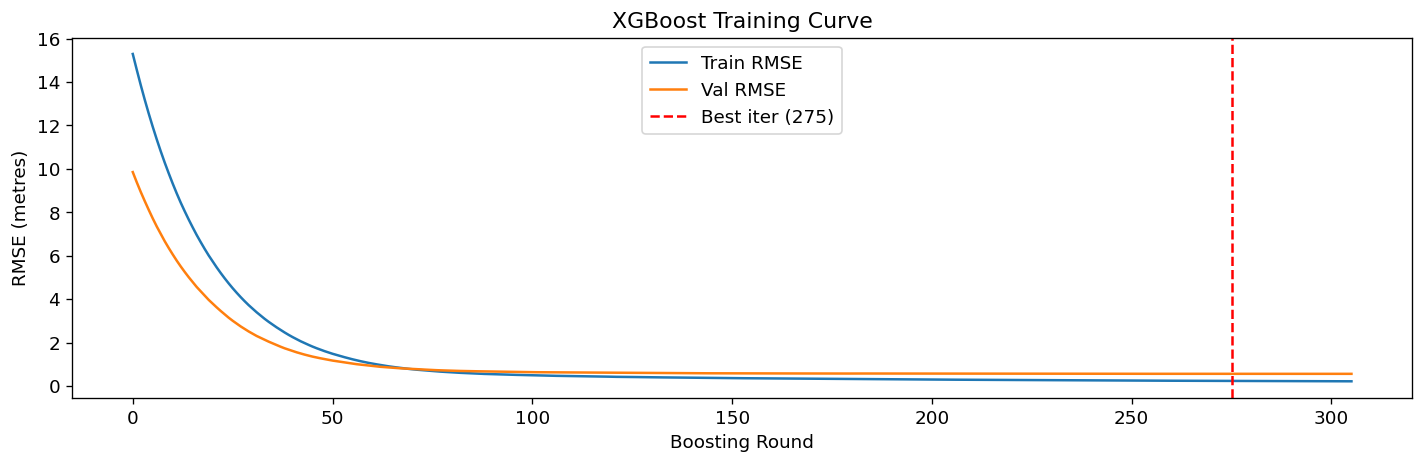

Final train RMSE : 0.2305 m
Final val   RMSE : 0.5566 m


In [7]:
# Training curve
results = model.evals_result()
train_rmse = results['validation_0']['rmse']
val_rmse_c = results['validation_1']['rmse']

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(train_rmse, label='Train RMSE', linewidth=1.5)
ax.plot(val_rmse_c, label='Val RMSE',   linewidth=1.5)
ax.axvline(model.best_iteration, color='red', linestyle='--', label=f'Best iter ({model.best_iteration})')
ax.set_xlabel('Boosting Round')
ax.set_ylabel('RMSE (metres)')
ax.set_title('XGBoost Training Curve')
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'xgboost_training_curve.png', dpi=150)
plt.show()
print(f'Final train RMSE : {train_rmse[model.best_iteration]:.4f} m')
print(f'Final val   RMSE : {val_rmse_c[model.best_iteration]:.4f} m')

## 4. Evaluate

In [8]:
def compute_metrics(actual, pred):
    a, p = np.array(actual, float), np.array(pred, float)
    rmse = np.sqrt(np.mean((a-p)**2))
    mae  = np.mean(np.abs(a-p))
    mask = a != 0
    mape = np.mean(np.abs((a[mask]-p[mask])/a[mask]))*100
    return rmse, mae, mape

val_pred  = model.predict(X_val)
test_pred = model.predict(X_test)

v_rmse, v_mae, v_mape = compute_metrics(y_val,  val_pred)
t_rmse, t_mae, t_mape = compute_metrics(y_test, test_pred)

results_table = pd.DataFrame({
    'Split':    ['Val', 'Test'],
    'RMSE (m)': [round(v_rmse,4), round(t_rmse,4)],
    'MAE (m)':  [round(v_mae,4),  round(t_mae,4)],
    'MAPE (%)': [round(v_mape,2), round(t_mape,2)],
})
print('=== XGBoost Aggregate Results ===')
display(results_table)

=== XGBoost Aggregate Results ===


,Split,RMSE (m),MAE (m),MAPE (%)
0,Val,0.5566,0.1957,6.10
1,Test,1.6818,0.4616,2.43


In [9]:
# Per-district test metrics
dist_map   = dict(zip(df['district_id'], df['district']))
test_df_cp = test_df.copy()
test_df_cp['gwl_pred']   = test_pred
test_df_cp['gwl_actual'] = y_test

dist_metrics = []
for did, grp in test_df_cp.groupby('district_id'):
    r, m, mp = compute_metrics(grp['gwl_actual'].values, grp['gwl_pred'].values)
    dist_metrics.append({'district': dist_map.get(did, did), 'rmse': round(r,4), 'mae': round(m,4), 'mape': round(mp,2)})
dm = pd.DataFrame(dist_metrics).sort_values('rmse', ascending=False)
print('=== Per-District Test RMSE ===')
display(dm.style.background_gradient(subset=['rmse'], cmap='YlOrRd'))

=== Per-District Test RMSE ===


,district,rmse,mae,mape
5,Dhule,6.456700,3.974400,7.500000
6,Jalgaon,3.359600,1.819200,9.300000
11,Nashik,0.850900,0.529500,3.470000
14,Satara,0.787900,0.557300,6.460000
10,Nandurbar,0.563400,0.425600,1.260000
7,Kolhapur,0.442300,0.356400,1.010000
15,Solapur,0.308100,0.236700,1.420000
13,Ratnagiri,0.265700,0.211900,1.270000
2,Aurangabad,0.196500,0.143000,2.310000
18,Washim,0.185800,0.143700,1.430000


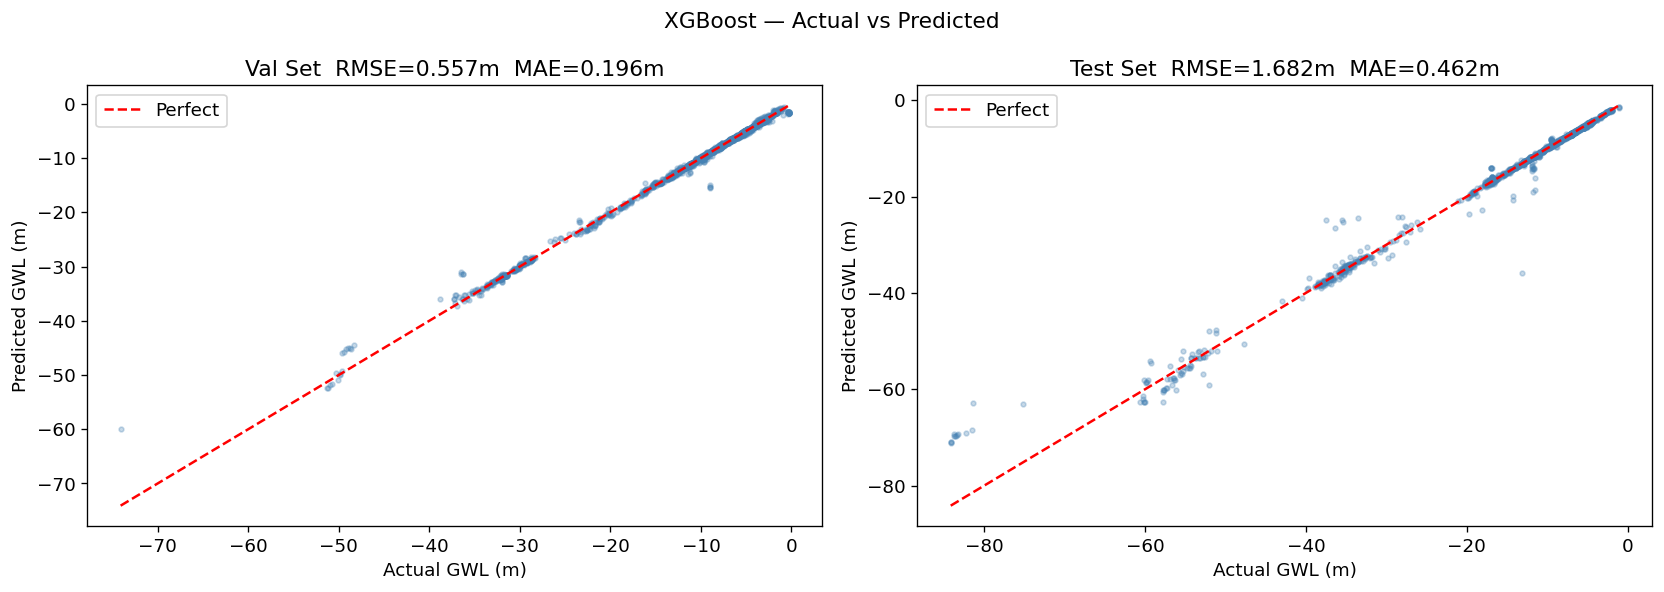

In [10]:
# Actual vs predicted scatter
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, title, actual, pred in [
    (axes[0], 'Val Set',  y_val,  val_pred),
    (axes[1], 'Test Set', y_test, test_pred),
]:
    ax.scatter(actual, pred, alpha=0.3, s=8, color='steelblue')
    mn, mx = min(actual.min(), pred.min()), max(actual.max(), pred.max())
    ax.plot([mn,mx],[mn,mx], 'r--', linewidth=1.5, label='Perfect')
    r, m, _ = compute_metrics(actual, pred)
    ax.set_title(f'{title}  RMSE={r:.3f}m  MAE={m:.3f}m')
    ax.set_xlabel('Actual GWL (m)')
    ax.set_ylabel('Predicted GWL (m)')
    ax.legend()
plt.suptitle('XGBoost — Actual vs Predicted', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'xgboost_scatter.png', dpi=150)
plt.show()

## 5. Feature Importance

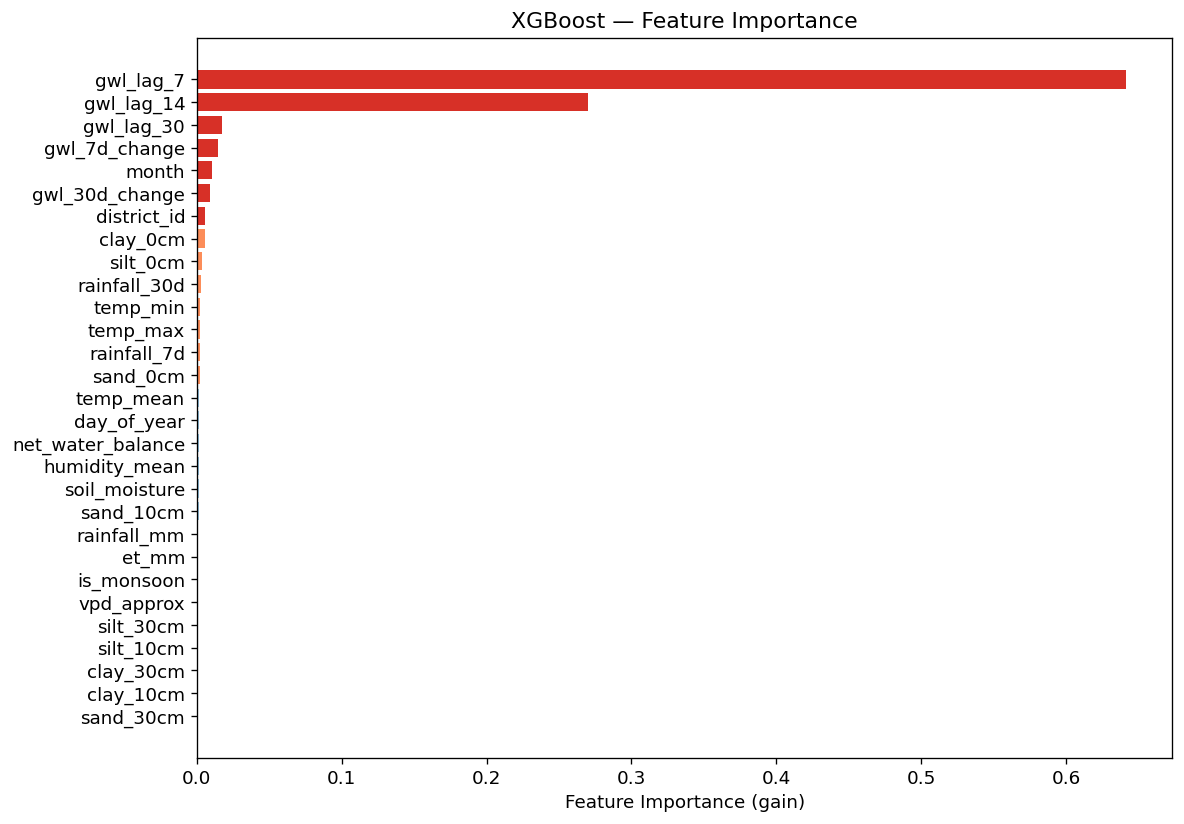

Top 10 features:


,feature,importance
0,gwl_lag_7,0.641446
1,gwl_lag_14,0.269761
2,gwl_lag_30,0.017113
3,gwl_7d_change,0.014504
16,month,0.010279
4,gwl_30d_change,0.008783
19,district_id,0.005689
21,clay_0cm,0.005664
22,silt_0cm,0.003838
7,rainfall_30d,0.002822


In [11]:
importance = pd.DataFrame({
    'feature':    available_features,
    'importance': model.feature_importances_,
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#d73027' if imp > importance['importance'].quantile(0.75) else
          '#fc8d59' if imp > importance['importance'].quantile(0.5)  else
          '#91bfdb' for imp in importance['importance']]
ax.barh(importance['feature'], importance['importance'], color=colors)
ax.invert_yaxis()
ax.set_xlabel('Feature Importance (gain)')
ax.set_title('XGBoost — Feature Importance')
plt.tight_layout()
plt.savefig(OUT_DIR / 'plots' / 'xgboost_feature_importance.png', dpi=150)
plt.show()
print('Top 10 features:')
display(importance.head(10))

## 6. SHAP Analysis
SHAP (SHapley Additive exPlanations) shows the actual contribution of each feature to each prediction — unlike feature importance, it accounts for feature interactions and gives directional insight.

In [14]:
!pip install shap

  Using cached numpy-2.4.4-cp311-cp311-win_amd64.whl.metadata (6.6 kB)
  Using cached numpy-2.2.6-cp311-cp311-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/554.9 kB ? eta -:--:--
   ------------------ --------------------- 262.1/554.9 kB ? eta -:--:--
   ---------------------------------------- 554.9/554.9 kB 2.3 MB/s  0:00:00
   ---------------------------------------- 0.0/38.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/38.1 MB ? eta -:--:--
    --------------------------------------- 0.5/38.1 MB 2.1 MB/s eta 0:00:18
   - -------------------------------------- 1.0/38.1 MB 1.9 MB/s eta 0:00:20
   - -------------------------------------- 1.3/38.1 MB 1.9 MB/s eta 0:00:20
   - -------------------------------------- 1.8/38.1 MB 2.0 MB/s eta 0:00:19
   -- ------------------------------------- 2.1/38.1 MB 2.0 MB/s eta 0:00:18
   -- ------------------------------------- 2.6/38.1 MB 2.0 MB/s eta 0:00:18
   --- -----------------------------

  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.2.6 which is incompatible.
gradio 4.10.0 requires markupsafe~=2.0, but you have markupsafe 3.0.2 which is incompatible.
gradio 4.10.0 requires numpy~=1.0, but you have numpy 2.2.6 which is incompatible.
mediapipe 0.10.21 requires numpy<2, but you have numpy 2.2.6 which is incompatible.
sentence-transformers 4.1.0 requires transformers<5.0.0,>=4.41.0, but you have transformers 5.5.4 which is incompatible.
streamlit 1.28.0 requires numpy<2,>=1.19.3, but you have numpy 2.2.6 which is incompatible.
streamlit 1.28.0 requires packaging<24,>=16.8, but you have packaging 26.2 which is incompatible.
tensorflow 2.21.0 requires protobuf<8.0.0,>=6.31.1, but you have protobuf 4.25.9 which is 

SHAP version: 0.51.0
Computing SHAP values (may take ~1 min) ...
Done.

--- SHAP Bar Plot (mean |SHAP value| per feature) ---


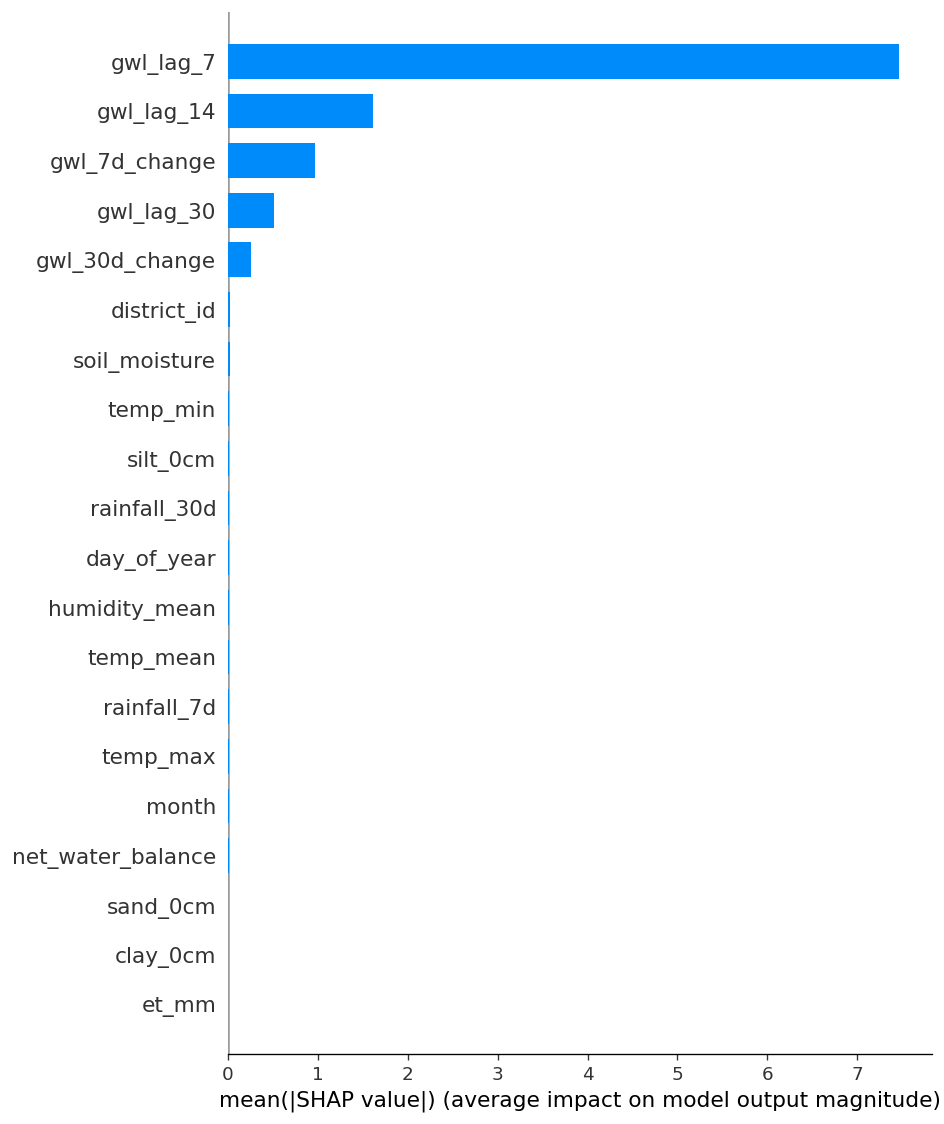


--- SHAP Beeswarm Plot (direction of effect) ---


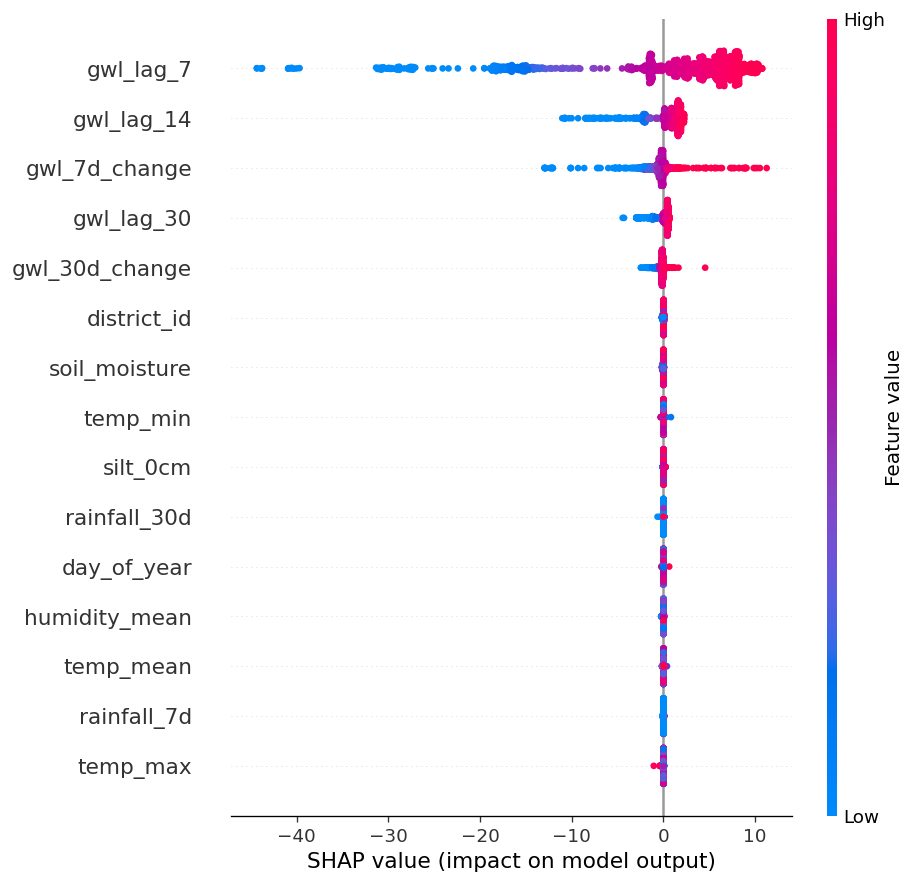


Top 10 by mean |SHAP|:


,feature,mean_shap
0,gwl_lag_7,7.462471
1,gwl_lag_14,1.611601
3,gwl_7d_change,0.969662
2,gwl_lag_30,0.515055
4,gwl_30d_change,0.256371
19,district_id,0.024770
9,soil_moisture,0.020538
12,temp_min,0.014320
22,silt_0cm,0.014037
7,rainfall_30d,0.014020


In [17]:
try:
    import shap
    print(f'SHAP version: {shap.__version__}')

    np.random.seed(42)
    sample_idx  = np.random.choice(len(X_test), size=min(2000, len(X_test)), replace=False)
    X_shap      = X_test[sample_idx]

    print('Computing SHAP values (may take ~1 min) ...')
    explainer   = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_shap)
    print('Done.')

    # Bar summary
    print('\n--- SHAP Bar Plot (mean |SHAP value| per feature) ---')
    shap.summary_plot(shap_values, X_shap, feature_names=available_features,
                      plot_type='bar', show=True, max_display=20)

    # Beeswarm — shows direction of effect
    print('\n--- SHAP Beeswarm Plot (direction of effect) ---')
    shap.summary_plot(shap_values, X_shap, feature_names=available_features,
                      show=True, max_display=15)

    # Save mean SHAP
    shap_mean = pd.DataFrame({
        'feature':   available_features,
        'mean_shap': np.abs(shap_values).mean(axis=0),
    }).sort_values('mean_shap', ascending=False)
    shap_mean.to_csv(OUT_DIR / 'xgboost_shap_values.csv', index=False)
    print('\nTop 10 by mean |SHAP|:')
    display(shap_mean.head(10))

except ImportError:
    print('[NOTE] shap not installed. Run: pip install shap')

## 7. Save Outputs

In [18]:
val_df_cp          = val_df.copy()
val_df_cp['gwl_pred']   = val_pred
val_df_cp['gwl_actual'] = y_val
val_df_cp['split']      = 'val'
test_df_cp['split']     = 'test'

preds_df = pd.concat([
    val_df_cp[['district','date','gwl_actual','gwl_pred','split']],
    test_df_cp[['district','date','gwl_actual','gwl_pred','split']],
], ignore_index=True)
preds_df.rename(columns={'gwl_pred':'gwl_predicted'}, inplace=True)
preds_df.to_csv(OUT_DIR / 'xgboost_predictions.csv', index=False)
dm.to_csv(OUT_DIR / 'xgboost_metrics.csv', index=False)
importance.to_csv(OUT_DIR / 'xgboost_feature_importance.csv', index=False)

print('Saved: xgboost_predictions.csv')
print('Saved: xgboost_metrics.csv')
print('Saved: xgboost_feature_importance.csv')
print('Saved: xgboost_training_curve.png')
print('Saved: xgboost_scatter.png')
print('Saved: xgboost_feature_importance.png')
print(f'\nAggregate test RMSE : {t_rmse:.4f} m')
print(f'Aggregate test MAE  : {t_mae:.4f} m')
print(f'Aggregate test MAPE : {t_mape:.2f} %')

Saved: xgboost_predictions.csv
Saved: xgboost_metrics.csv
Saved: xgboost_feature_importance.csv
Saved: xgboost_training_curve.png
Saved: xgboost_scatter.png
Saved: xgboost_feature_importance.png

Aggregate test RMSE : 1.6818 m
Aggregate test MAE  : 0.4616 m
Aggregate test MAPE : 2.43 %
